**Import the necessary libraries**

In [10]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import load_wine
from sklearn.model_selection import train_test_split
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score, classification_report
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay


In [2]:
# Load the dataset
wine = load_wine()

# Convert features into a Pandas DataFrame
df = pd.DataFrame(wine.data, columns=wine.feature_names)

# Add the target column
df["class"] = wine.target

# define target integers to class names
df["class"] = df["class"].map({
    0: "class_0",
    1: "class_1",
    2: "class_2"
})

# Display the first five rows
df.head()


,alcohol,malic_acid,ash,alcalinity_of_ash,magnesium,total_phenols,flavanoids,nonflavanoid_phenols,proanthocyanins,color_intensity,hue,od280/od315_of_diluted_wines,proline,class
0,14.23,1.71,2.43,15.6,127.0,2.80,3.06,0.28,2.29,5.64,1.04,3.92,1065.0,class_0
1,13.20,1.78,2.14,11.2,100.0,2.65,2.76,0.26,1.28,4.38,1.05,3.40,1050.0,class_0
2,13.16,2.36,2.67,18.6,101.0,2.80,3.24,0.30,2.81,5.68,1.03,3.17,1185.0,class_0
3,14.37,1.95,2.50,16.8,113.0,3.85,3.49,0.24,2.18,7.80,0.86,3.45,1480.0,class_0
4,13.24,2.59,2.87,21.0,118.0,2.80,2.69,0.39,1.82,4.32,1.04,2.93,735.0,class_0


**Generate descriptive statistics**

In [3]:
df.describe()

,alcohol,malic_acid,ash,alcalinity_of_ash,magnesium,total_phenols,flavanoids,nonflavanoid_phenols,proanthocyanins,color_intensity,hue,od280/od315_of_diluted_wines,proline
count,178.000000,178.000000,178.000000,178.000000,178.000000,178.000000,178.000000,178.000000,178.000000,178.000000,178.000000,178.000000,178.000000
mean,13.000618,2.336348,2.366517,19.494944,99.741573,2.295112,2.029270,0.361854,1.590899,5.058090,0.957449,2.611685,746.893258
std,0.811827,1.117146,0.274344,3.339564,14.282484,0.625851,0.998859,0.124453,0.572359,2.318286,0.228572,0.709990,314.907474
min,11.030000,0.740000,1.360000,10.600000,70.000000,0.980000,0.340000,0.130000,0.410000,1.280000,0.480000,1.270000,278.000000
25%,12.362500,1.602500,2.210000,17.200000,88.000000,1.742500,1.205000,0.270000,1.250000,3.220000,0.782500,1.937500,500.500000
50%,13.050000,1.865000,2.360000,19.500000,98.000000,2.355000,2.135000,0.340000,1.555000,4.690000,0.965000,2.780000,673.500000
75%,13.677500,3.082500,2.557500,21.500000,107.000000,2.800000,2.875000,0.437500,1.950000,6.200000,1.120000,3.170000,985.000000
max,14.830000,5.800000,3.230000,30.000000,162.000000,3.880000,5.080000,0.660000,3.580000,13.000000,1.710000,4.000000,1680.000000


**Count the number of instances for each class**

In [4]:
print(df["class"].value_counts())

class
class_1    71
class_0    59
class_2    48
Name: count, dtype: int64


**Split the data**

In [5]:
#Separate features and target variable
# Features
X = df.drop("class", axis=1)

# Target
y = df["class"]

print("Features shape:", X.shape)
print("Target shape:", y.shape)

Features shape: (178, 13)
Target shape: (178,)


In [6]:
#Split into training and testing sets. 80% of the data to train the model and 20% to test its performance
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training set:", X_train.shape)
print("Testing set:", X_test.shape)

Training set: (142, 13)
Testing set: (36, 13)


**Check missing values**

In [7]:
print(df.isnull().sum())

alcohol                         0
malic_acid                      0
ash                             0
alcalinity_of_ash               0
magnesium                       0
total_phenols                   0
flavanoids                      0
nonflavanoid_phenols            0
proanthocyanins                 0
color_intensity                 0
hue                             0
od280/od315_of_diluted_wines    0
proline                         0
class                           0
dtype: int64


No missing values.

**Data Visualization**

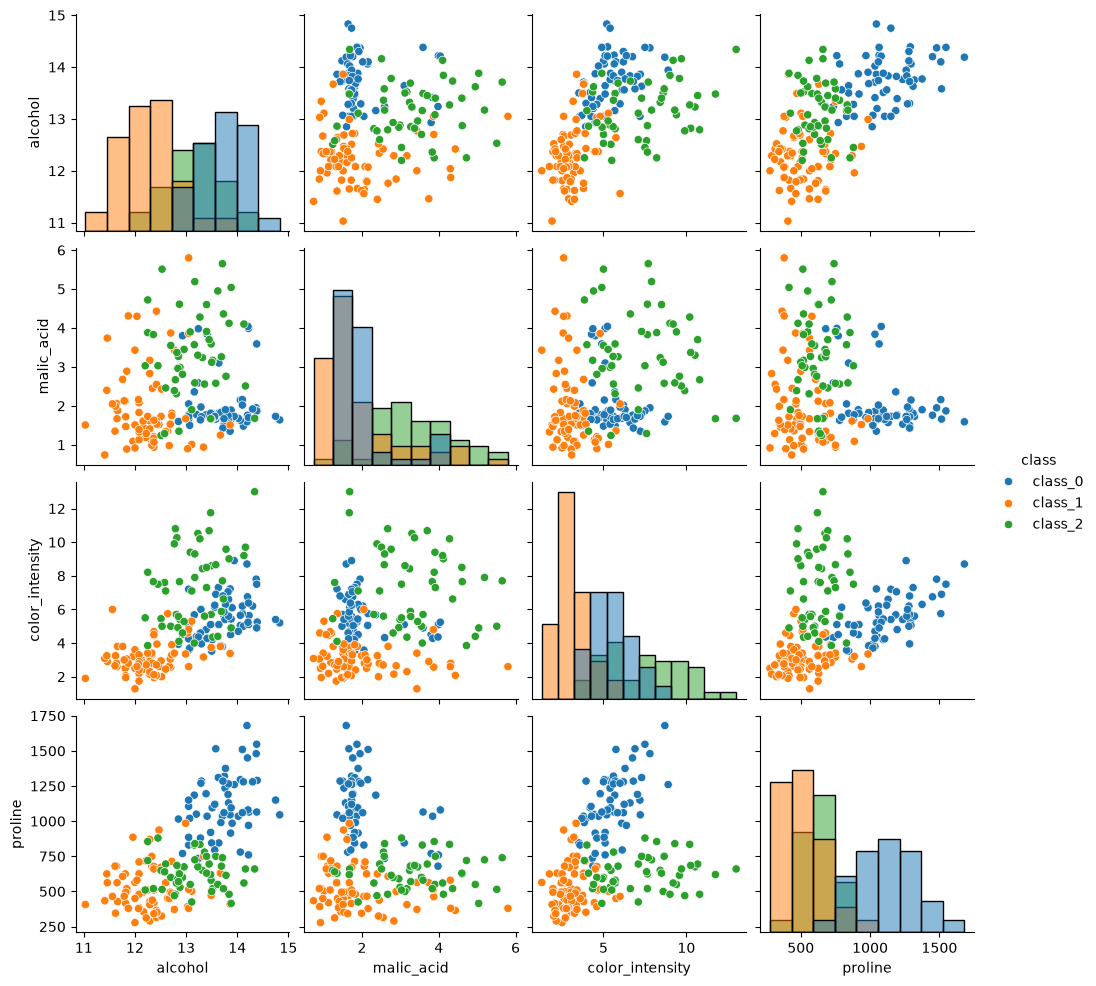

In [8]:
#Use Seaborn's pairplot to visualize the relationships between features, colored by class.
sns.pairplot(
    df,
    vars=["alcohol", "malic_acid", "color_intensity", "proline"],
    hue="class",
    diag_kind="hist"
)

plt.show()

The pairplot shows the relationships between different chemical features. The different colors represent the three wine classess. Where the colors Overlaps indicate that certain classes may be harder to separate using those features alone.

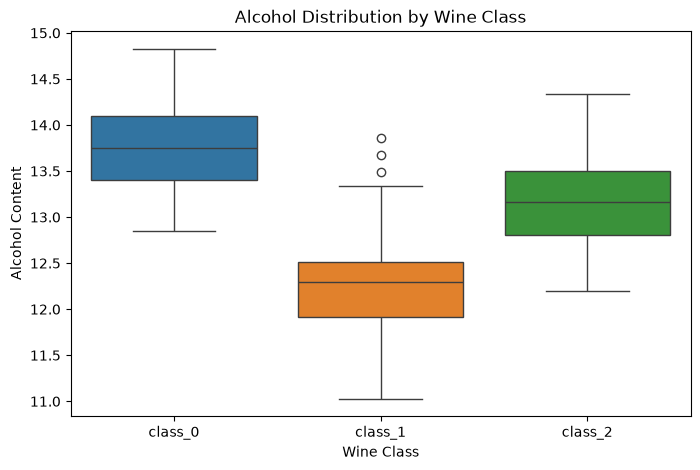

In [9]:
#Create a boxplot of alcohol grouped by class to visualize the distribution
plt.figure(figsize=(8, 5))

sns.boxplot(
    data=df,
    x="class",
    y="alcohol",
    hue="class",
    legend=False
)

plt.title("Alcohol Distribution by Wine Class")
plt.xlabel("Wine Class")
plt.ylabel("Alcohol Content")

plt.show()

Class 1 has some indentified outliers

**Model Building**

In [12]:
# Scale features
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# Train Logistic regression model
model = LogisticRegression(max_iter=1000, random_state=42)
model.fit(X_train_scaled, y_train)

# Make predictions
y_pred = model.predict(X_test_scaled)

# Evaluate
print("Accuracy:", accuracy_score(y_test, y_pred))
print(classification_report(y_test, y_pred))

Accuracy: 0.9722222222222222
              precision    recall  f1-score   support

     class_0       1.00      1.00      1.00        12
     class_1       0.93      1.00      0.97        14
     class_2       1.00      0.90      0.95        10

    accuracy                           0.97        36
   macro avg       0.98      0.97      0.97        36
weighted avg       0.97      0.97      0.97        36



An accuracy of 97.22 means the model correctly classified approximately 97 out of every 100 samples
Note the following:
Precision means how many samples predicted as a particular wine class actually belong to that class
Recall: means how many actual samples of a wine class the model correctly identified
F1-score gives the balance between precision and recall
Support is the number of actual samples belonging to each class.

Based on this;
For Class 0, the model achieved 100% precision, recall, and F1-score, meaning all 12 wine samples were correctly classified without any errors.
For Class 1, the model achieved 93% precision, 100% recall, and 97% F1-score. 
For Class 2, the model achieved 100% precision, 90% recall, and 95% F1-score. 

In [13]:
# Compare actual and predicted values
results = pd.DataFrame({
    "Actual": y_test.values,
    "Predicted": y_pred
})

print(results.head(10))

    Actual Predicted
0  class_0   class_0
1  class_2   class_1
2  class_0   class_0
3  class_1   class_1
4  class_1   class_1
5  class_0   class_0
6  class_0   class_0
7  class_1   class_1
8  class_1   class_1
9  class_2   class_2


of the 10 rows printed, the model correctly predict 9